This notebook is a quick walk through of how to generate ERICA image sequences using ORG module. 

Original [ERICA](https://github.com/LauraKateYoung/ERICA) has already provided a detailed tutorial. 

ORG module is a wrapper I wrote for my own experiment which required realistic cone reflectance change and output a continuous video instead of single image. 


**Install uv**

This repository is set up with [uv](https://docs.astral.sh/uv/). Follow the instructions from the [uv installation page](https://docs.astral.sh/uv/getting-started/installation/).

For MacOS the simplest is

```
brew install uv
```

**Setup the environment**

Setup the project environment and install dependencies

```
uv sync
```


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
sys.path.append('../')

from importlib import reload

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['image.cmap'] = 'gray' 

from ORG import pipeline

In [2]:
current_directory = '/home/siruil/Code/ERICA'  # the directory where all the parameters config are saved
retina = pipeline.retina(current_directory)

`system_parameters_myAOSLO.yaml` is the realistic setting for Oxford AOSLO, which will generate a rectangle image, operate at 30 Hz.

Frame rate is determined by: ```number_scan_lines_including_flyback/frequency_fast_scanner_Hz```. 

In [3]:
retina.load_config()    # load all config files

System parameters file: /home/siruil/Code/ERICA/System_parameters/system_parameters_myAOSLO.yaml
Cone reflectance parameter file: /home/siruil/Code/ERICA/Reflectance_parameters/cone_reflectance_parameters.yaml
Eye movements parameter file: /home/siruil/Code/ERICA/Fixation_parameters/fixation_parameters_default.yaml
Unscaled mosaic grid file: /home/siruil/Code/ERICA/isetbio_retina/mosaic_00.mat


Original ERICA has pre-generated retina mosaic using reaction diffusion model. 
However the size of the mosaic is limited.

An alternative way to generate mosaic is using a simulation tool call [ISETBio](https://github.com/isetbio/isetbio), 
which contains many meta-data about the cone mosaic, including cone types, outer segment length and etc. 

A pre-computed 15 deg x 15 deg ISETBio mosaic centred at fovea is given in `../isetbio_retina/mosaic_00.mat`

In [4]:
retina.isetbio_mosaic() # load mosaic from isetbio
retina.mosaic

{'aperture2diameter': array(0.79),
 'aperture2gaussian_sigma': array(0.28849957),
 'cone_aperture_um': array([7.26062612, 7.78653678, 6.9323176 , ..., 6.86849908, 7.5065294 ,
        6.91064556], shape=(367837,)),
 'cone_position_deg': array([[-3.08302272,  7.49981178],
        [-5.57070222,  7.4993323 ],
        [ 2.24583373,  7.49965195],
        ...,
        [-0.65019958, -7.49952391],
        [ 4.21804397, -7.49881287],
        [-1.59485813, -7.49818356]], shape=(367837, 2)),
 'cone_position_um': array([[ -855.89746094,  2054.35546875],
        [-1533.90734863,  2054.2265625 ],
        [  625.46203613,  2054.3125    ],
        ...,
        [ -182.29814148, -2054.27807617],
        [ 1166.37475586, -2054.08691406],
        [ -445.33480835, -2053.91772461]], shape=(367837, 2)),
 'cone_ratios': array([0.60067639, 0.2996599 , 0.09966371, 0.        ]),
 'cone_spacings_deg': array([0.03425146, 0.0368491 , 0.0326748 , ..., 0.03234217, 0.03546045,
        0.03255565], shape=(367837,)),
 'c

In original ERICA, cone intensities were randomly sampled from a normal distribution.

In this pipeline, you can toggle between cone intensities sampled from normal distribution (`normal`) and realistic cone intensities calculated based on their outer segment length (`interference`). 

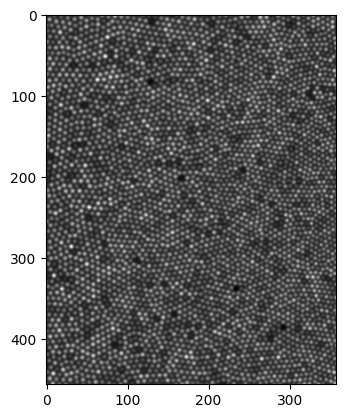

In [5]:
# toggle cone reflectance mode by changing the 'distribution' between `interference` and `normal`
retina.cone_reflectance_parameters['distribution'] = 'normal'

# this function not only load mosaic, but also pre-calculate retina parameters, so always run it before running `make_aoslo_image` if you overwrite any parameters
retina.isetbio_mosaic() 

# this function is the core function of generating aoslo image
im = retina.make_aoslo_image(eye_motion_arcmin=None, noise=False)
plt.imshow(im)

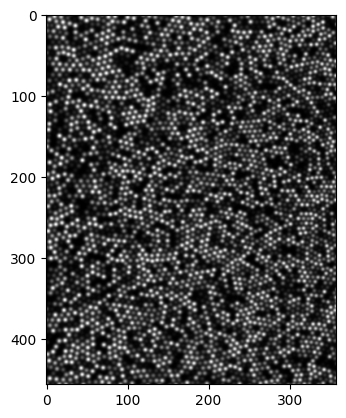

In [6]:
# toggle cone reflectance mode by changing the 'distribution' between `interference` and `normal`
retina.cone_reflectance_parameters['distribution'] = 'interference'

# this function not only load mosaic, but also pre-calculate retina parameters, so always run it before running `make_aoslo_image` if you overwrite any parameters
retina.isetbio_mosaic() 

# this function is the core function of generating aoslo image
im = retina.make_aoslo_image(eye_motion_arcmin=None, noise=False)
plt.imshow(im)

Generate one image takes a few seconds. 

There is a script `run_trial_parallel.py` for generate one trial using parallel process, 
which could speed up the dataset generation process if you need a long trial.

The `run_trial_parallel.py` saves image sequences and eye motions into `.npz`, dump all config setting into a single `.yaml`, with an option to write out `.mp4`.